# Grover Solver — Deployment Configuration

**Task A:** Find a valid configuration for three binary features using Grover's algorithm on an ideal simulator.

| Bit | Feature | Meaning of 1 |
|---|---|---|
| P | Public API | enabled |
| A | Authentication | enabled |
| W | Background worker | enabled |

Output order is **(P, A, W)**. This notebook implements a classical checker, a manual reversible phase oracle (X, CX, CCX only), Grover search, a numerical check against theory, an interactive probability explorer, and a cost discussion.

## Setup

Install the required packages once before running the notebook:

```bash
pip install numpy matplotlib ipywidgets
```

**Requirements:** Python 3.9 or newer, `numpy`, `matplotlib`, `ipywidgets` (for the interactive slider in Cell 5).

## Requirements and Boolean logic

| # | Requirement | Boolean form |
|---|---|---|
| R1 | At least one execution mode | `P ∨ W` |
| R2 | API requires authentication | `P → A`, i.e. `¬P ∨ A` |
| R3 | API and worker not together | `¬(P ∧ W)` |

Valid configuration: `V(P,A,W) = (P ∨ W) ∧ (¬P ∨ A) ∧ ¬(P ∧ W)`.

Case split gives an oracle-friendly form:
- `P = 0`: R1 forces `W = 1`, giving the term `¬P ∧ W` (A is free).
- `P = 1`: R3 forces `W = 0` and R2 forces `A = 1`, giving the term `P ∧ A ∧ ¬W`.

So `V = (¬P ∧ W) ∨ (P ∧ A ∧ ¬W)`. The two terms can never be true together (one needs `P = 0`, the other `P = 1`), so OR equals XOR, and XOR is what the oracle uses.

Expected solutions: `001` (worker only), `011` (worker + auth), `110` (API + auth), so M = 3 out of N = 8.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

def valid(p, a, w):
    return bool((p or w) and (not p or a) and not (p and w))

configs = [f"{i:03b}" for i in range(8)]          # strings are in (P, A, W) order
solutions = [x for x in configs if valid(*map(int, x))]

# The two-term form used by the oracle must agree with the full requirements.
def valid_oracle_form(p, a, w):
    return bool((not p and w) or (p and a and not w))
assert all(valid(*map(int, x)) == valid_oracle_form(*map(int, x)) for x in configs)

print("Valid configurations:", solutions)
print("Total configurations (N):", len(configs))
print("Valid configurations (M):", len(solutions))

Valid configurations: ['001', '011', '110']
Total configurations (N): 8
Valid configurations (M): 3


## Simulator, gates and qubit mapping

Eight qubits, 2⁸ = 256 amplitudes. Simulator index bit `q` is the value of qubit `q`.

| Qubit | Role |
|---|---|
| 2 (`P`) | search qubit: public API |
| 1 (`A`) | search qubit: authentication |
| 0 (`W`) | search qubit: background worker |
| 3 (`t1`) | workspace: `¬P ∧ W` |
| 4 (`t2`) | workspace: `P ∧ A` |
| 5 (`t3`) | workspace: `P ∧ A ∧ ¬W` |
| 6 (`flag`) | workspace: validity flag `t1 ⊕ t3` |
| 7 (`phase`) | phase ancilla |

**Bit-order:** `P, A, W = 2, 1, 0` makes `i & 7` read as the string `PAW` when formatted with `f"{i:03b}"`, so plot labels, solution lookups and sampling all use the same (P, A, W) order as the checker.

Phase ancillia is a helper qubit used to carry out phase kickback computations.

In [2]:
P, A, W, t1, t2, t3, flag, phase = 2, 1, 0, 3, 4, 5, 6, 7
N = 2**8
SEARCH = [P, A, W]

X = np.array([[0, 1], [1, 0]])
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)

def gate(s, q, matrix):
    out = s.copy()
    mask = 1 << q
    for i in range(len(s)):
        if not i & mask:
            j = i | mask
            a, b = s[i], s[j]
            out[i] = matrix[0, 0]*a + matrix[0, 1]*b
            out[j] = matrix[1, 0]*a + matrix[1, 1]*b
    return out

def xgate(s, q):
    return gate(s, q, X)

def hgate(s, q):
    return gate(s, q, H)

def mcx(s, controls, target):
    """CX for one control, CCX for two."""
    out = s.copy()
    mask = 1 << target
    for i in range(len(s)):
        if not i & mask and all(i & (1 << q) for q in controls):
            j = i | mask
            out[i], out[j] = s[j], s[i]
    return out

def initial():
    s = np.zeros(N, dtype=complex)
    s[0] = 1
    s = xgate(s, phase)
    s = hgate(s, phase)          # phase ancilla in |->
    for q in SEARCH:
        s = hgate(s, q)          # uniform superposition over 8 configurations
    return s

## Manual phase oracle

Computes `flag = (¬P ∧ W) ⊕ (P ∧ A ∧ ¬W)` into workspace using X/CX/CCX, flips the phase ancilla controlled on `flag` (phase kickback: `|−⟩` turns the bit flip into a −1 phase on valid states), then runs the same steps in reverse to restore every workspace qubit to 0.

In [3]:
def oracle(s):
    # t1 = NOT P AND W
    s = xgate(s, P)
    s = mcx(s, [P, W], t1)
    s = xgate(s, P)

    # t2 = P AND A
    s = mcx(s, [P, A], t2)

    # t3 = t2 AND NOT W  (= P AND A AND NOT W)
    s = xgate(s, W)
    s = mcx(s, [t2, W], t3)
    s = xgate(s, W)

    # flag = t1 XOR t3
    s = mcx(s, [t1], flag)
    s = mcx(s, [t3], flag)

    # Phase kickback onto |->
    s = mcx(s, [flag], phase)

    # Uncompute flag, then temporaries in reverse order
    s = mcx(s, [t3], flag)
    s = mcx(s, [t1], flag)

    s = xgate(s, W)
    s = mcx(s, [t2, W], t3)
    s = xgate(s, W)
    s = mcx(s, [P, A], t2)

    s = xgate(s, P)
    s = mcx(s, [P, W], t1)
    s = xgate(s, P)
    return s

## Oracle verification

For each of the eight inputs (workspace = 0, phase ancilla in `|−⟩`) check that:
1. valid inputs get a `−1` phase and invalid inputs get `+1`;
2. the input bits are unchanged;
3. all four workspace qubits (`t1, t2, t3, flag`) are back to 0.



In [4]:
WORK_MASK = (1 << t1) | (1 << t2) | (1 << t3) | (1 << flag)
INPUT_MASK = (1 << P) | (1 << A) | (1 << W)

results = []
for x in configs:
    bits = list(map(int, x))
    s = np.zeros(N, dtype=complex)
    i = sum(b << q for b, q in zip(bits, SEARCH))
    s[i] = 1 / np.sqrt(2)
    s[i | (1 << phase)] = -1 / np.sqrt(2)

    out = oracle(s)
    sign = -1 if valid(*bits) else 1

    phase_ok = np.allclose(out, sign * s)
    nz = np.flatnonzero(np.abs(out) > 1e-12)
    inputs_ok = all((j & INPUT_MASK) == (i & INPUT_MASK) for j in nz)
    workspace_ok = all((j & WORK_MASK) == 0 for j in nz)
    results.append((x, valid(*bits), "-" if sign == -1 else "+", phase_ok, inputs_ok, workspace_ok))

# Print the results as a formatted table
yes_no = lambda flag: "Yes" if flag else "No"
header = ["Config (P A W)", "Valid", "Phase", "Phase correct", "Inputs kept", "Workspace restored"]
rows = [[x, yes_no(v), ph, yes_no(p_ok), yes_no(i_ok), yes_no(w_ok)]
        for x, v, ph, p_ok, i_ok, w_ok in results]

widths = [max(len(header[c]), *(len(r[c]) for r in rows)) for c in range(len(header))]
line = lambda cells: " | ".join(str(c).center(w) for c, w in zip(cells, widths))

print(line(header))
print("-+-".join("-" * w for w in widths))
for r in rows:
    print(line(r))

assert all(r[3] and r[4] and r[5] for r in results)
print("\nOracle verification passed.")

Config (P A W) | Valid | Phase | Phase correct | Inputs kept | Workspace restored
---------------+-------+-------+---------------+-------------+-------------------
     000       |   No  |   +   |      Yes      |     Yes     |        Yes        
     001       |  Yes  |   -   |      Yes      |     Yes     |        Yes        
     010       |   No  |   +   |      Yes      |     Yes     |        Yes        
     011       |  Yes  |   -   |      Yes      |     Yes     |        Yes        
     100       |   No  |   +   |      Yes      |     Yes     |        Yes        
     101       |   No  |   +   |      Yes      |     Yes     |        Yes        
     110       |  Yes  |   -   |      Yes      |     Yes     |        Yes        
     111       |   No  |   +   |      Yes      |     Yes     |        Yes        

Oracle verification passed.


## Diffusion, Grover search and numerical check against theory

The diffuser reflects amplitudes about their mean (`H·X·CCZ·X·H` on the three search qubits; CCZ is built as `H · CCX · H`). 

With M = 3 and N = 8, `θ = arcsin(√(M/N))` and the success probability after k iterations is `sin²((2k+1)θ)`. The optimal count is `k* = π/(4θ) − ½ ≈ 0.69`, so **k = 1** (84.4%) is the right choice. The cell asserts that the simulator matches theory for k = 0…4.

k | simulated | theory
0 | 37.5000% | 37.5000%
1 | 84.3750% | 84.3750%
2 | 2.3437% | 2.3437%
3 | 99.0234% | 99.0234%
4 | 11.8652% | 11.8652%

Optimal iteration count k* = 1


IntSlider(value=1, description='Iterations:', max=4)

Output()

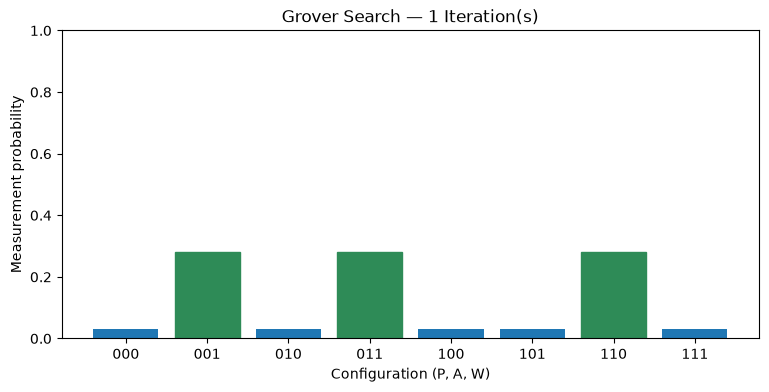

Valid-state probability: 84.37%
Theoretical probability: 84.38%


In [8]:
def diffuser(s):
    for q in SEARCH:
        s = hgate(s, q)
        s = xgate(s, q)

    # CCZ = H(target) . CCX . H(target)
    s = hgate(s, W)
    s = mcx(s, [P, A], W)
    s = hgate(s, W)

    for q in SEARCH:
        s = xgate(s, q)
        s = hgate(s, q)

    return -s  # global phase correction

def search(k):
    s = initial()
    for _ in range(k):
        s = oracle(s)
        s = diffuser(s)
    return s

def probabilities(s):
    """Marginal probability of each (P, A, W) configuration; index c reads as f'{c:03b}' = 'PAW'."""
    return np.array([
        sum(abs(s[i])**2 for i in range(N) if (i & 7) == c)
        for c in range(8)
    ])

M = len(solutions)
theta = np.arcsin(np.sqrt(M / len(configs)))
k_opt = int(round(np.pi / (4 * theta) - 0.5))
sol_idx = [int(x, 2) for x in solutions]

def theory(k):
    return np.sin((2*k + 1) * theta)**2

# Numerical check: simulator vs closed-form prediction
print("k | simulated | theory")
for k in range(5):
    sim = probabilities(search(k))[sol_idx].sum()
    print(f"{k} | {sim:.4%} | {theory(k):.4%}")
    assert np.isclose(sim, theory(k))
print(f"\nOptimal iteration count k* = {k_opt}")

def explore(k):
    probs = probabilities(search(k))
    observed = probs[sol_idx].sum()

    fig, ax = plt.subplots(figsize=(9, 4))
    bars = ax.bar(configs, probs)
    for bar, x in zip(bars, configs):
        if x in solutions:
            bar.set_color("seagreen")

    ax.set_ylim(0, 1)
    ax.set_ylabel("Measurement probability")
    ax.set_xlabel("Configuration (P, A, W)")
    ax.set_title(f"Grover Search — {k} Iteration(s)")
    plt.show()

    print(f"Valid-state probability: {observed:.2%}")
    print(f"Theoretical probability: {theory(k):.2%}")

slider = widgets.IntSlider(value=k_opt, min=0, max=4, step=1,
                           description="Iterations:")
display(slider)
display(widgets.interactive_output(explore, {"k": slider}))
explore(k_opt)

## Measurement and verified result

Run the optimal number of iterations, sample the final distribution, pick the most frequently observed valid configuration, and **verify it with the classical checker** before printing it by feature name.

In [6]:
k = k_opt
shots = 5000

s = search(k)
probs = probabilities(s)
rng = np.random.default_rng(42)
samples = rng.choice(configs, size=shots, p=probs)

counts = {x: int(np.sum(samples == x)) for x in configs}
success = sum(counts[x] for x in solutions)
best = max(solutions, key=lambda x: counts[x])

# Verification of the reported configuration with the classical checker
assert valid(*map(int, best)), "Grover returned an invalid configuration"

print(f"Grover iterations: {k}")
print(f"Measurement shots: {shots}")
print(f"Observed valid results: {success / shots:.2%}  (theory {theory(k):.2%})")
print(f"Counts: {counts}")
print(f"Most frequent valid result: {best}  -> verified by classical checker")

names = ["Public API", "Authentication", "Background worker"]
print("\nSelected deployment:")
for name, bit in zip(names, best):
    print(f"  {name}: {'Enabled' if bit == '1' else 'Disabled'}")

print("\nClassical reference:")
print(f"  Configurations checked: {len(configs)}")
print(f"  Valid configurations found: {len(solutions)}")

Grover iterations: 1
Measurement shots: 5000
Observed valid results: 84.26%  (theory 84.38%)
Counts: {'000': 145, '001': 1457, '010': 174, '011': 1393, '100': 157, '101': 147, '110': 1363, '111': 164}
Most frequent valid result: 001  -> verified by classical checker

Selected deployment:
  Public API: Disabled
  Authentication: Disabled
  Background worker: Enabled

Classical reference:
  Configurations checked: 8
  Valid configurations found: 3


## Cost and Benefit

Comparing the classical search with the Grover search for this problem (N = 8 configurations, M = 3 valid ones).

| | Classical enumeration | Grover (my notebook) |
|---|---|---|
| How many checks | At most 8 (about 2.7 on average if I check in random order) | 1 oracle call (the best number is about 0.69, so I use 1) |
| Cost of each check | One Boolean expression | One oracle, which is 19 gates on 8 qubits, plus the diffuser |
| Answer | Always exact | Probabilistic: 84.4% success at k = 1, so I verify the result |
| Simulation cost | None | 2⁸ = 256 amplitudes, and every gate updates all of them |

Grover needs about √(N/M) oracle calls, while a classical search needs about N/M. That is a quadratic speedup, but it describes how the cost grows as the problem gets bigger. It doesn't say anything about this small problem.

With only 8 configurations, Grover gives no real advantage. The classical check is one line of Boolean logic, while one oracle call is a 19-gate circuit, and simulating it on a normal computer costs far more than just checking all 8 configurations. Also, I built the oracle from the same validity rules the classical checker already uses, so it doesn't find anything the classical code couldn't. This notebook shows that the algorithm works, not that it is faster on this specific problem.

## Manual Circuit Drawing

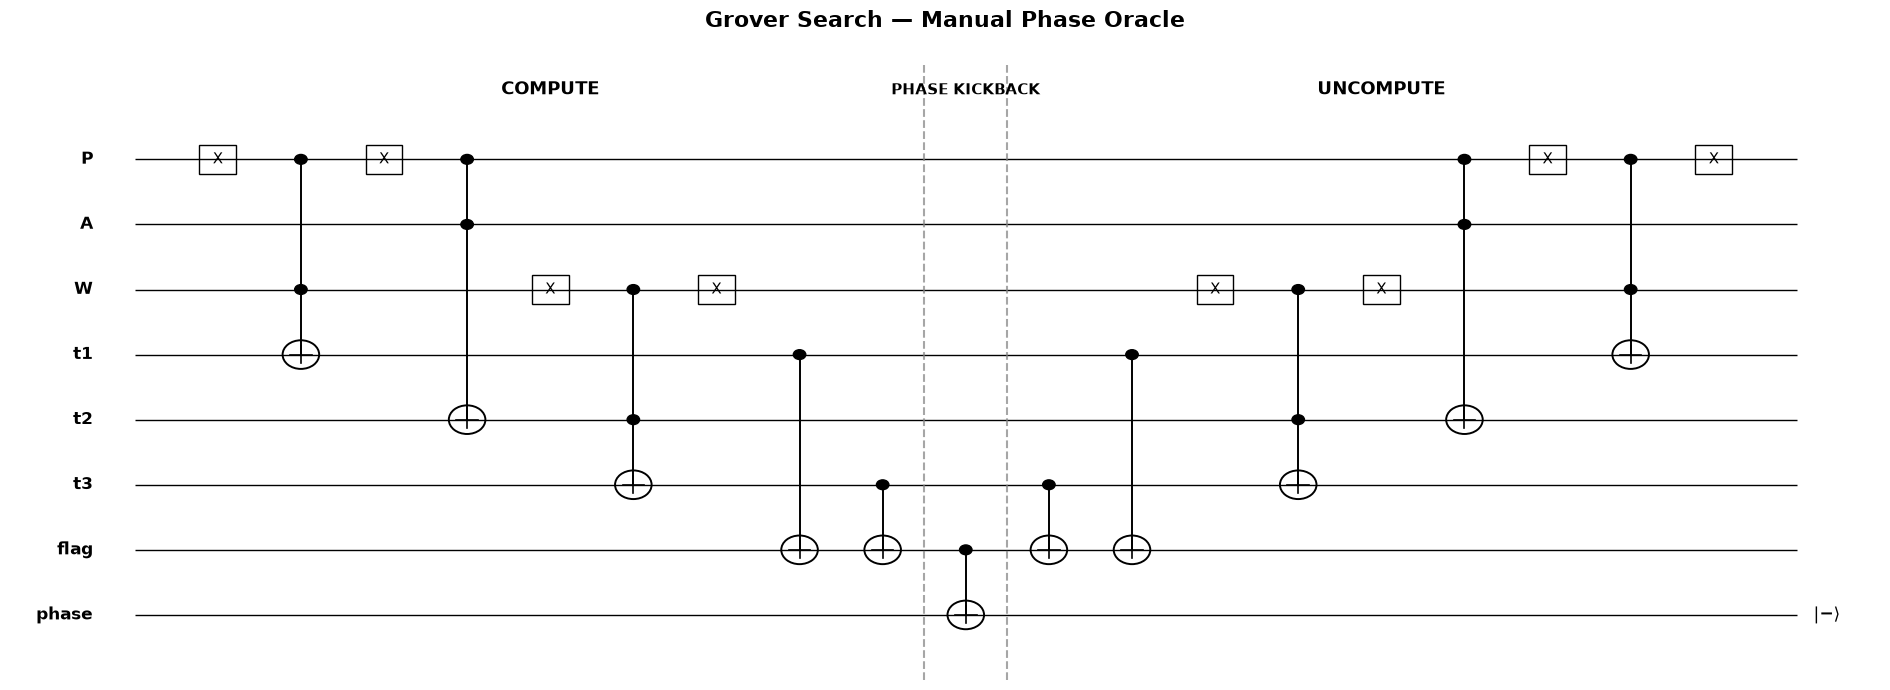

In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle

# Qubit order
qubits = ["P", "A", "W", "t1", "t2", "t3", "flag", "phase"]
y = {q: 7 - i for i, q in enumerate(qubits)}

fig, ax = plt.subplots(figsize=(19, 7))

# Draw qubit wires and labels
for q in qubits:
    ax.hlines(y[q], 0, 20, color="black", linewidth=1)
    ax.text(-0.5, y[q], q, ha="right", va="center",
            fontsize=12, fontweight="bold")

# Gate drawing functions
def draw_x(q, x):
    ax.add_patch(Rectangle((x-0.22, y[q]-0.22), 0.44, 0.44,
                           facecolor="white", edgecolor="black"))
    ax.text(x, y[q], "X", ha="center", va="center", fontsize=11)

def draw_controlled(controls, target, x):
    ys = [y[q] for q in controls + [target]]
    ax.vlines(x, min(ys), max(ys), color="black", linewidth=1.4)

    for q in controls:
        ax.add_patch(Circle((x, y[q]), 0.075, color="black"))

    ax.add_patch(Circle((x, y[target]), 0.22,
                        facecolor="white", edgecolor="black",
                        linewidth=1.4))
    ax.plot([x-0.13, x+0.13], [y[target], y[target]],
            color="black", linewidth=1.2)
    ax.plot([x, x], [y[target]-0.13, y[target]+0.13],
            color="black", linewidth=1.2)

# Exact oracle gate sequence
gates = [
    ("X", "P"),
    ("CCX", ["P", "W"], "t1"),
    ("X", "P"),
    ("CCX", ["P", "A"], "t2"),
    ("X", "W"),
    ("CCX", ["t2", "W"], "t3"),
    ("X", "W"),
    ("CX", ["t1"], "flag"),
    ("CX", ["t3"], "flag"),
    ("CX", ["flag"], "phase"),

    # Uncomputation: reverse order
    ("CX", ["t3"], "flag"),
    ("CX", ["t1"], "flag"),
    ("X", "W"),
    ("CCX", ["t2", "W"], "t3"),
    ("X", "W"),
    ("CCX", ["P", "A"], "t2"),
    ("X", "P"),
    ("CCX", ["P", "W"], "t1"),
    ("X", "P")
]

# Draw gates
for col, operation in enumerate(gates, start=1):
    x = col

    if operation[0] == "X":
        draw_x(operation[1], x)
    else:
        draw_controlled(operation[1], operation[2], x)

# Stage separators
ax.axvline(9.5, color="gray", linestyle="--", alpha=0.7)
ax.axvline(10.5, color="gray", linestyle="--", alpha=0.7)

ax.text(5, 8.0, "COMPUTE", ha="center", fontsize=13,
        fontweight="bold")
ax.text(10, 8.0, "PHASE KICKBACK", ha="center", fontsize=11,
        fontweight="bold")
ax.text(15, 8.0, "UNCOMPUTE", ha="center", fontsize=13,
        fontweight="bold")

ax.text(20.2, y["phase"], "|−⟩", va="center", fontsize=12)

ax.set_xlim(-1.5, 21)
ax.set_ylim(-1, 8.5)
ax.axis("off")
ax.set_title("Grover Search — Manual Phase Oracle",
             fontsize=16, fontweight="bold", pad=25)

plt.tight_layout()
plt.show()